# Tambura Oil Field: Which Power Option Deserves the Capital? (Case Study #9)

**Source paper:** Jamal, M.N. & Sudrajat, O.Y. (2022). *Project Capital Rationing using Discounted Cash Flow Method, Sensitivity Analysis and Monte Carlo Simulation: Case Study Tambura Oil Development.* European Journal of Business and Management Research, 7(6), 287-296. https://doi.org/10.24018/ejbmr.2022.7.6.1760 (open access, CC BY-NC 4.0)

**Primary lens: Capital Budgeting.** Three mutually exclusive ways to power one progressive-cavity pump (PCP) insert: lay a cable (high capex), install a genset (middle), or rent a genset (low capex, high opex). The decision is which option gets scarce capital.

**Honesty disclosure.** Paper text was read via automated full-text extraction of the open-access PDF, not a manual read. The paper does NOT publish: its PSC split, its oil price, its yearly cash flows, or the probability distributions in its Monte Carlo. Sections 1-2 use the paper's own published numbers. Sections 3-5 are a labeled, illustrative reconstruction and do not reproduce the authors' workbook.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from scipy.optimize import brentq
pd.set_option('display.width',140)
OPT={1:'Option-1 Cable',2:'Option-2 Own genset',3:'Option-3 Rental'}
# CONFIRMED from the paper (USD million unless noted)
paper=pd.DataFrame({
 'Capex':[2.39,1.89,0.39],'Opex (life-of-project)':[1.38,3.25,5.46],
 'Cost recovery':[3.90,5.27,5.98],'Net entitlement':[2.58,2.23,1.84],
 'NPV @10.45%':[1.44,1.33,1.41],'IRR':[0.36,0.41,1.76],
 'Payback (yrs)':[1.79,1.58,0.48],'Profitability index':[2.02,2.11,5.44],'Discounted PI':[1.57,1.66,4.41]},
 index=[OPT[k] for k in (1,2,3)])
paper

,Capex,Opex (life-of-project),Cost recovery,Net entitlement,NPV @10.45%,IRR,Payback (yrs),Profitability index,Discounted PI
Option-1 Cable,2.39,1.38,3.90,2.58,1.44,0.36,1.79,2.02,1.57
Option-2 Own genset,1.89,3.25,5.27,2.23,1.33,0.41,1.58,2.11,1.66
Option-3 Rental,0.39,5.46,5.98,1.84,1.41,1.76,0.48,5.44,4.41


## 1. Capital budgeting arithmetic from the paper's own numbers
Rank by NPV and Option-1 wins by US$0.03M. Rank by capital efficiency and the order inverts. Everything below is arithmetic on the confirmed table, not simulation.

In [2]:
t=paper[['Capex','NPV @10.45%']].copy()
t['NPV per $ of capex (own calc)']=t['NPV @10.45%']/t['Capex']
t['NPV rank']=t['NPV @10.45%'].rank(ascending=False).astype(int)
t['Capex rank (1=cheapest)']=t['Capex'].rank().astype(int)
print(t.round(3))
gap=1.44-1.41; freed=2.39-0.39
print(f"\nNPV given up by choosing Option-3 over Option-1: US${gap:.2f}M ({gap/1.44:.1%} of Option-1 NPV)")
print(f"Capex avoided: US${freed:.2f}M ({freed/2.39:.1%} of Option-1 capex)")
print(f"Freed capital must earn only NPV >= US${gap:.2f}M, i.e. NPV/capex >= {gap/freed:.3f}, for Option-3 + redeployment to beat Option-1.")

                     Capex  NPV @10.45%  NPV per $ of capex (own calc)  NPV rank  Capex rank (1=cheapest)
Option-1 Cable        2.39         1.44                          0.603         1                        3
Option-2 Own genset   1.89         1.33                          0.704         3                        2
Option-3 Rental       0.39         1.41                          3.615         2                        1

NPV given up by choosing Option-3 over Option-1: US$0.03M (2.1% of Option-1 NPV)
Capex avoided: US$2.00M (83.7% of Option-1 capex)
Freed capital must earn only NPV >= US$0.03M, i.e. NPV/capex >= 0.015, for Option-3 + redeployment to beat Option-1.


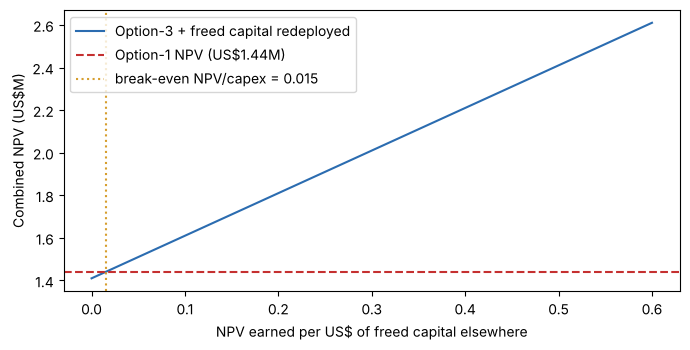

In [3]:
# Break-even redeployment: what NPV per $ must the freed US$2.00M earn elsewhere?
ratios=np.linspace(0,0.6,61)
combo=1.41+freed*ratios
fig,ax=plt.subplots(figsize=(7,3.6))
ax.plot(ratios,combo,color='#2b6cb0',label='Option-3 + freed capital redeployed')
ax.axhline(1.44,color='#c53030',ls='--',label='Option-1 NPV (US$1.44M)')
ax.axvline(gap/freed,color='#d69e2e',ls=':',label=f'break-even NPV/capex = {gap/freed:.3f}')
ax.set_xlabel('NPV earned per US$ of freed capital elsewhere'); ax.set_ylabel('Combined NPV (US$M)'); ax.legend(); plt.tight_layout(); plt.show()

## 2. Reconstructed cash flows (ILLUSTRATIVE, calibrated)
The paper publishes totals, not annual cash flows. This model uses: 2023 capex; 2024-2030 production declining exponentially from the paper's ~180 BOPD peak, calibrated so cumulative oil equals the paper's 0.4 MMbbl; life-of-project opex spread evenly; declining-balance (25%) depreciation recovered through PSC cost recovery; and a contractor profit share applied to revenue above cost recovery.

**Assumptions the paper does not give:** oil price (US$70/bbl is my illustrative choice), and the net contractor share. The share is calibrated per option so each reconstructed NPV equals the paper's published NPV at 10.45%. The three calibrated shares differ, which itself tells you the simplified model is missing real PSC mechanics (taxes, FTP, DMO). IRR, payback, and undiscounted totals are then checked, not forced.

In [4]:
R_DISC=0.1045; CAPEX={1:2.39,2:1.89,3:0.39}; OPEX={1:1.38,2:3.25,3:5.46}
PAPER_NPV={1:1.44,2:1.33,3:1.41}; PRICE=70.0
RES=0.4e6; PEAK=180*365
D=brentq(lambda d: PEAK*sum(np.exp(-d*k) for k in range(7))-RES,1e-4,1)
Q=np.array([PEAK*np.exp(-D*k) for k in range(7)])
def cashflows(k,s,prod=1.0,price=1.0,opx=1.0,cx=1.0):
    C=CAPEX[k]*cx; O=OPEX[k]*opx
    R=np.concatenate([[0],Q*prod*PRICE*price/1e6]); o=np.concatenate([[0],np.full(7,O/7)])
    dep=np.zeros(8); bal=C
    for t in range(1,8):
        d=bal*0.25 if t<7 else bal; dep[t]=d; bal-=d
    cr=np.zeros(8); carry=0.0
    for t in range(1,8):
        avail=o[t]+dep[t]+carry; cr[t]=min(avail,R[t]); carry=avail-cr[t]
    cap=np.zeros(8); cap[0]=C
    return cr+s*(R-cr)-o-cap
npv=lambda c,r=R_DISC: sum(c[t]/(1+r)**t for t in range(len(c)))
S={k:brentq(lambda s: npv(cashflows(k,s))-PAPER_NPV[k],0.001,0.95) for k in (1,2,3)}
rows=[]
for k in (1,2,3):
    c=cashflows(k,S[k]); irr=brentq(lambda x: npv(c,x),0.001,100)
    cum=np.cumsum(c); i=int(np.argmax(cum>=0)); pb=i-1+(-cum[i-1])/c[i] if i>0 else 0
    rows.append([OPT[k],round(S[k],3),round(npv(c),2),round(c.sum(),2),paper.iloc[k-1]['Net entitlement'],round(irr,2),paper.iloc[k-1]['IRR'],round(pb,2),paper.iloc[k-1]['Payback (yrs)']])
pd.DataFrame(rows,columns=['Option','calibrated share','recon NPV','recon undiscounted net','paper net entitlement','recon IRR','paper IRR','recon payback','paper payback'])

,Option,calibrated share,recon NPV,recon undiscounted net,paper net entitlement,recon IRR,paper IRR,recon payback,paper payback
0,Option-1 Cable,0.124,1.44,3.01,2.58,0.30,0.36,2.52,1.79
1,Option-2 Own genset,0.116,1.33,2.65,2.23,0.33,0.41,2.34,1.58
2,Option-3 Rental,0.098,1.41,2.16,1.84,1.09,1.76,0.85,0.48


**Reading the check.** NPV matches by construction. Undiscounted net cash overshoots the paper's (the reconstruction is more generous than the authors' model). IRR and payback differ visibly, most for Option-3, because its capex is so small that IRR is hypersensitive to first-year timing. Do not read the reconstruction's IRRs as the authors'.

## 3. Monte Carlo: which option holds up under the paper's own ranges?
Ranges taken from the paper's scenario analysis: oil price -24%/+21%, oil production -40%/+120% (my reading of the paper's range; ambiguous in extraction), capex +/-10%, inflation 2.6%-8.24% around a 4.04% base. **Distribution shape is NOT stated in the paper**; I use triangular(min, base, max). Opex is scaled by cumulative inflation over a 4-year mid-life. I add one correlation the paper does not state: oil price and inflation, rho = 0.4, via a Cholesky Gaussian copula. 10,000 trials per option, same draws across options so the comparison is paired.

In [5]:
from scipy.stats import norm
rng=np.random.default_rng(42); N=10000; RHO=0.4
def tri_inv(u,a,m,b):
    fc=(m-a)/(b-a); return np.where(u<fc,a+np.sqrt(u*(b-a)*(m-a)),b-np.sqrt((1-u)*(b-a)*(b-m)))
z1=rng.standard_normal(N); z2=RHO*z1+np.sqrt(1-RHO**2)*rng.standard_normal(N)
price=tri_inv(norm.cdf(z1),0.76,1.0,1.21)
infl=tri_inv(norm.cdf(z2),0.026,0.0404,0.0824)
opx=((1+infl)/(1.0404))**4
prod=tri_inv(rng.random(N),0.6,1.0,2.2)
cx=tri_inv(rng.random(N),0.9,1.0,1.1)
res={}
for k in (1,2,3):
    res[k]=np.array([npv(cashflows(k,S[k],prod[i],price[i],opx[i],cx[i])) for i in range(N)])
summ=pd.DataFrame({OPT[k]:{'mean NPV':res[k].mean(),'sd':res[k].std(),'P5':np.percentile(res[k],5),'P95':np.percentile(res[k],95),'P(NPV<0)':(res[k]<0).mean(),'mean NPV per $ capex':res[k].mean()/CAPEX[k]} for k in res}).T
print(summ.round(3))
print('\nPaper reports a 10-30% probability of NPV<0 collectively (per-option values not tabulated).')
d=res[3]-res[1]
print(f"P(Option-3 NPV > Option-1 NPV) = {(d>0).mean():.1%}; mean difference = US${d.mean():.2f}M")

                     mean NPV     sd     P5    P95  P(NPV<0)  mean NPV per $ capex
Option-1 Cable          2.053  0.861  0.823  3.613       0.0                 0.859
Option-2 Own genset     1.896  0.802  0.752  3.352       0.0                 1.003
Option-3 Rental         1.882  0.675  0.916  3.108       0.0                 4.825

Paper reports a 10-30% probability of NPV<0 collectively (per-option values not tabulated).
P(Option-3 NPV > Option-1 NPV) = 19.8%; mean difference = US$-0.17M


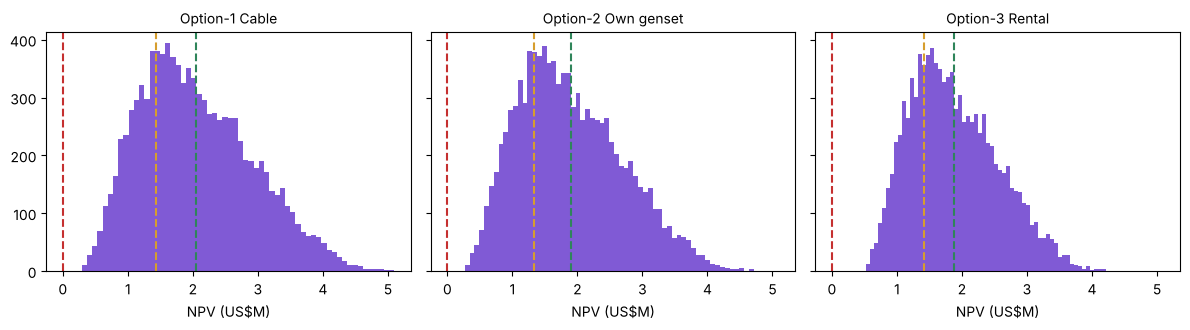

In [6]:
fig,axs=plt.subplots(1,3,figsize=(12,3.4),sharex=True,sharey=True)
for ax,k in zip(axs,(1,2,3)):
    ax.hist(res[k],bins=60,color='#805ad5'); ax.axvline(0,color='#c53030',ls='--'); ax.axvline(PAPER_NPV[k],color='#d69e2e',ls='--'); ax.axvline(res[k].mean(),color='#2f855a',ls='--')
    ax.set_title(OPT[k],fontsize=10); ax.set_xlabel('NPV (US$M)')
plt.tight_layout(); plt.show()

In [7]:
# Corner check vs the paper's scenario range (abstract: lowest NPV negative as low as US$1.09M, highest US$2.62M)
ow=((1.0824)/1.0404)**4; ob=((1.026)/1.0404)**4
worst={k:npv(cashflows(k,S[k],0.6,0.76,ow,1.1)) for k in (1,2,3)}
best={k:npv(cashflows(k,S[k],2.2,1.21,ob,0.9)) for k in (1,2,3)}
print(pd.DataFrame({'all-worst corner':worst,'base':PAPER_NPV,'all-best corner':best}).rename(index=OPT).round(2))
print('Paper abstract: scenario NPV from about -1.09 to +2.62 (US$M, not split by option in the abstract).')
print('Reconstruction worst corner stays positive: it cannot reproduce the paper downside. That is a disclosed gap, not a finding. The best corner (up to US$5.6M) also overshoots the paper US$2.62M maximum.')

                     all-worst corner  base  all-best corner
Option-1 Cable                   0.01  1.44             5.57
Option-2 Own genset             -0.02  1.33             5.18
Option-3 Rental                  0.29  1.41             4.62
Paper abstract: scenario NPV from about -1.09 to +2.62 (US$M, not split by option in the abstract).
Reconstruction worst corner stays positive: it cannot reproduce the paper downside. That is a disclosed gap, not a finding. The best corner (up to US$5.6M) also overshoots the paper US$2.62M maximum.


## 4. What the paper's capital-rationing logic would let a board do
The paper reports no post-decision outcome: this is a prospective feasibility study. So no claim is made about what happened after Option-3 was recommended. What the numbers support is a decision rule: when capital is rationed, rank by NPV per scarce dollar and by downside, not by headline NPV alone.

In [8]:
out={'paper_confirmed':paper.reset_index().to_dict(orient='records'),
 'calibrated_share':{OPT[k]:float(S[k]) for k in S},
 'break_even_npv_per_capex':gap/freed,
 'mc':{OPT[k]:{m:float(summ.loc[OPT[k],m]) for m in summ.columns} for k in (1,2,3)},
 'p_opt3_beats_opt1':float((d>0).mean()),
 'note':'Illustrative reconstruction; see README honesty disclosure.'}
json.dump(out,open('notebook_reconstruction_output.json','w'),indent=1)
print('saved')

saved
